<a href="https://colab.research.google.com/github/Fhini/APS_lab/blob/main/APS_lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [75]:
# import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline

In [76]:
# Load the dataset

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series((data.target == 0).astype(int),name="malignant")
print(y.value_counts())
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape: (569, 30)
Target shape: (569,)
Class names: ['malignant' 'benign']


In [77]:
# Examine the class distribution

class_counts = y.value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": data.target_names,
    "Count": class_counts.values,
    "Probability": class_counts.values / len(y)
})

print(class_distribution)

       Class  Count  Probability
0  malignant    357     0.627417
1     benign    212     0.372583


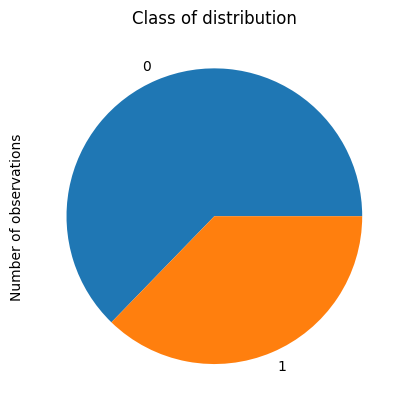

In [78]:
class_distribution.plot(
    x = "Class",
    y = "Count",
    kind = "pie",
    legend = False,
    color = ["blue","green"]
)

plt.ylabel("Number of observations")
plt.title("Class of distribution")
plt.xticks(rotation = 0)
plt.show()

In [79]:
# Creating training and testing samples

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state= 42,
    stratify=y
)

print("Training size:",len(y_train))
print("Testing size:", len(y_test))

print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting proportions:")
print(y_test.value_counts(normalize=True).sort_index())


Training size: 455
Testing size: 114

Training proportions:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Testing proportions:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


In [80]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter = 1000)
)

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [81]:
probabilities = model.predict_proba(X_test)
print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [82]:
results = pd.DataFrame({
    "Actual_class": y_test.values,
    "P_malignant": probabilities[:,0],
    "P_benign" : probabilities[:,1]
})

results


,Actual_class,P_malignant,P_benign
0,0,9.996354e-01,0.000365
1,1,1.074660e-08,1.000000
2,0,9.574321e-01,0.042568
3,1,4.238127e-01,0.576187
4,0,4.908445e-01,0.509155
...,...,...,...
109,0,9.998799e-01,0.000120
110,0,9.996350e-01,0.000365
111,0,8.844442e-01,0.115556
112,1,5.083901e-01,0.491610


In [83]:
results["Actual_label"] = results["Actual_class"].map({
    0: "Malignant",
    1: "Benign"
})

print(
    results[
        ["Actual_label", "P_malignant", "P_benign"]
    ].head(10)
)

  Actual_label   P_malignant  P_benign
0    Malignant  9.996354e-01  0.000365
1       Benign  1.074660e-08  1.000000
2    Malignant  9.574321e-01  0.042568
3       Benign  4.238127e-01  0.576187
4    Malignant  4.908445e-01  0.509155
5    Malignant  9.993840e-01  0.000616
6       Benign  2.384659e-01  0.761534
7    Malignant  9.989878e-01  0.001012
8    Malignant  9.994313e-01  0.000569
9    Malignant  9.892324e-01  0.010768


In [84]:
threshold = 0.50
results["Predicted_malignant"] = (
    results["P_malignant"] >= threshold
).astype(int)

results["Predicted_label"] = results[
    "Predicted_malignant"
].map({
    1: "Malignant",
    0: "Benign"
})

print(
    results[
        [
            "Actual_label",
            "P_malignant",
            "Predicted_label"
        ]
    ].head(10)
)

  Actual_label   P_malignant Predicted_label
0    Malignant  9.996354e-01       Malignant
1       Benign  1.074660e-08          Benign
2    Malignant  9.574321e-01       Malignant
3       Benign  4.238127e-01          Benign
4    Malignant  4.908445e-01          Benign
5    Malignant  9.993840e-01       Malignant
6       Benign  2.384659e-01          Benign
7    Malignant  9.989878e-01       Malignant
8    Malignant  9.994313e-01       Malignant
9    Malignant  9.892324e-01       Malignant


In [85]:
for threshold in [0.30, 0.50, 0.70]:
  predictions = (
      results["P_malignant"] >= threshold
  ).astype(int)

  print(
      f"Threshold = {threshold}: "
      f"Predicted malignant cases = {predictions.sum()}"
  )

Threshold = 0.3: Predicted malignant cases = 76
Threshold = 0.5: Predicted malignant cases = 74
Threshold = 0.7: Predicted malignant cases = 72


In [86]:
#construct a confusion matrix

actual_malignant = (y_test.values == 0).astype(int)

for threshold in [0.30, 0.50, 0.70]:
  predicted_malignant = (
      probabilities[:, 0] >= threshold
  ).astype(int)

  cm = confusion_matrix(
      actual_malignant,
      predicted_malignant
  )

  print(f"\nThreshold = {threshold}")
  print(cm)


Threshold = 0.3
[[38  4]
 [ 0 72]]

Threshold = 0.5
[[39  3]
 [ 1 71]]

Threshold = 0.7
[[41  1]
 [ 1 71]]


In [87]:
# Predict class labels for the test set
Y_pred = model.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(
    "Sklearn accuracy:",
    accuracy_score(y_test, Y_pred)
)
print(
    "Sklearn precision:",
    precision_score(y_test, Y_pred)
)
print(
    "Sklearn recall:",
    recall_score(y_test, Y_pred)
)
print(
    "Sklearn f1-score:",
    f1_score(y_test, Y_pred)
)


Sklearn accuracy: 0.9649122807017544
Sklearn precision: 0.975
Sklearn recall: 0.9285714285714286
Sklearn f1-score: 0.9512195121951219


In [90]:
# compare all metrics across thresholds

metric_results = []

for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:
  y_pred_threshold = (
      probabilities[:, 1] >= threshold
  ).astype(int)

  tn, fp, fn, tp = confusion_matrix(
      y_test,
      y_pred_threshold,
      labels=[0,1]
  ).ravel()

  metric_results.append({
      "Threshold": threshold,
      "TN": tn,
      "FP": fp,
      "FN": fn,
      "TP": tp,
      "Accuracy": accuracy_score(y_test, y_pred_threshold),
      "Precision": precision_score(y_test, y_pred_threshold),
      "Recall": recall_score(y_test, y_pred_threshold),
      "F1 Score": f1_score(y_test, y_pred_threshold)
    })

metric_results = pd.DataFrame(metric_results)

metric_results

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1 Score
0,0.1,67,5,1,41,0.947368,0.891304,0.976190,0.931818
1,0.3,71,1,1,41,0.982456,0.976190,0.976190,0.976190
2,0.5,71,1,3,39,0.964912,0.975000,0.928571,0.951220
3,0.7,72,0,4,38,0.964912,1.000000,0.904762,0.950000
4,0.9,72,0,9,33,0.921053,1.000000,0.785714,0.880000
